### Exporatory Data Analysis

For this project, I will be using the wine dataset from scikit-learn

In [250]:
# import modules
from sklearn import datasets 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Model imports
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

In [251]:
# create the random_seed to be used for reproducibility
r = 985

In [252]:
# load dataset
wine=datasets.load_wine()

# convert to DataFrame
df = pd.DataFrame(wine.data, columns = wine.feature_names)
df['label'] = wine.target
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,label
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


As we can see, this dataset contains 178 rows and 13 different features and one added feature which is the class of wine, we will be using this as the target for later

In [253]:
# Checking for missing values
df.isna().sum()

# Dataset has no missing values

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
label                           0
dtype: int64

In [254]:
# Checking distribution of labels
np.bincount(df["label"])
df.label.value_counts(normalize=True).round(3)

# As we can see, the dataset is balanced enough for basic ml tasks.


label
1    0.399
0    0.331
2    0.270
Name: proportion, dtype: float64

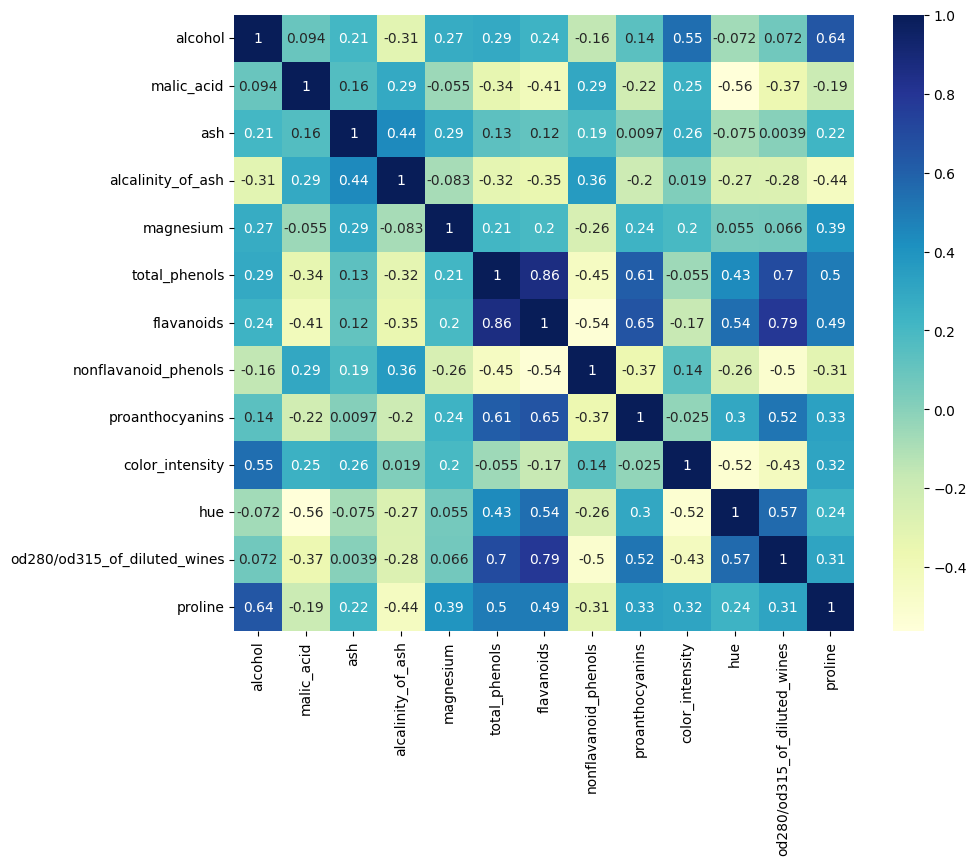

In [255]:
# Checking feature correlations as a heatmap minus label column
plt.figure(figsize=(10,8))
sns.heatmap(df.iloc[:,:-1].corr(), annot=True, cmap="YlGnBu")
plt.show()

2 of the correlations are quite high, the 2 being :
flavanoids & total phenols = 0.86
flavanoids & od280/od315_of_diluted_wines = 0.79

If needed later on, I will keep flavanoids and remove the other 2.

### Choice of algorithms

For this project I will be doing 3 different algorithms, Decision Tree, kNN and SVM. SVM will be the one done from scratch.

## SVM

As i am not as familiar with SVM, I will be doing it from scratch to give me a better idea of how it works.

In [256]:
class SVM:

    # Model initialization
    def __init__(self, iterations=1000, lr=0.01, lambdaa=0.01):

        self.lambdaa = lambdaa
        self.iterations = iterations
        self.lr = lr
        self.w = None
        self.b = None

    # Initialize weights and bias
    def initialize_parameters(self, X):
        # Get number and shape of features
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0
 
    # Gradient descent function to update weights and bias
    def gradient_descent(self, X, y):
        #
        y_ = np.where(y <= 0, -1, 1)
        for i, x in enumerate(X):
            if y_[i] * (np.dot(x, self.w) - self.b) >= 1:
                dw = 2 * self.lambdaa * self.w
                db = 0
            else:
                dw = 2 * self.lambdaa * self.w - np.dot(x, y_[i])
                db = y_[i]
            self.update_parameters(dw, db)

    # Function to update weights and bias
    def update_parameters(self, dw, db):
        self.w = self.w - self.lr * dw
        self.b = self.b - self.lr * db

    # Fit data to the model
    def fit(self, X, y):
        self.initialize_parameters(X)
        for i in range(self.iterations):
            self.gradient_descent(X, y)

    # Make predictions
    def predict(self, X):
        # get the outputs
        output = np.dot(X, self.w) - self.b
        # get the signs of the labels depending on if it's greater/less than zero
        label_signs = np.sign(output)
        #set predictions to 0 if they are less than or equal to -1 else set them to 1
        predictions = np.where(label_signs <= -1, 0, 1)
        return predictions

Now to train and test the model

In [257]:
# Create train/test split for classification
X_svm = df.drop(columns=['label']).values
y_svm = df['label'].values

X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(X_svm, y_svm, test_size=0.2, random_state=r)

# Train SVM model
model = SVM()
model.fit(X_train_svm, y_train_svm)
predictions = model.predict(X_test_svm)

In [258]:
# Check for over/underfitting by also getting train accuracy
train_predictions = model.predict(X_train_svm)
train_accuracy = accuracy_score(y_train_svm, train_predictions)

print(f"SVM Train Accuracy: {train_accuracy:.4f}")
print(f"SVM Test Accuracy: {accuracy_score(y_test_svm, predictions):.4f}")

SVM Train Accuracy: 0.6408
SVM Test Accuracy: 0.7222


In [259]:
# Scikit-learn SVM without scalar for comparison
pipeline = Pipeline([
    ('svm', SVC(random_state=r))
])
pipeline.fit(X_train_svm, y_train_svm)
predictions = pipeline.predict(X_test_svm)

accuracy_score(y_test_svm, predictions)

0.7777777777777778

In [260]:
# Scikit-learn SVM with scalar for comparison
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=r))
])
pipeline.fit(X_train_svm, y_train_svm)
predictions = pipeline.predict(X_test_svm)

accuracy_score(y_test_svm, predictions)

0.9722222222222222

In [261]:
# Cross-validation for SVM
svm_cv_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=r))
])

# Perform 5-fold cross-validation
svm_cv_scores = cross_val_score(svm_cv_pipeline, X_svm, y_svm, cv=5, scoring='accuracy')

print(f"SVM Cross-Validation Scores: {svm_cv_scores}")
print(f"SVM Mean CV Accuracy: {svm_cv_scores.mean():.4f} (+/- {svm_cv_scores.std() * 2:.4f})")

SVM Cross-Validation Scores: [1.         0.97222222 0.94444444 1.         1.        ]
SVM Mean CV Accuracy: 0.9833 (+/- 0.0444)


### Decision tree

In [262]:
# Create train/test split for Decision Tree
X_dt = df.drop(columns=['label']).values
y_dt = df['label'].values

X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(X_dt, y_dt, test_size=0.2, random_state=r)

# Train Decision Tree model
dt_model = DecisionTreeClassifier(random_state=r)
dt_model.fit(X_train_dt, y_train_dt)

# Make predictions on test set
dt_predictions = model.predict(X_test_dt)

# Calculate test accuracy
dt_test_accuracy = accuracy_score(y_test_dt, dt_predictions)

In [263]:
# Check for overfitting by comparing train and test accuracy
dt_train_predictions = dt_model.predict(X_train_dt)
dt_train_accuracy = accuracy_score(y_train_dt, dt_train_predictions)
print(f"Decision Tree Train Accuracy: {dt_train_accuracy:.4f}")
print(f"Decision Tree Test Accuracy: {dt_test_accuracy:.4f}")

Decision Tree Train Accuracy: 1.0000
Decision Tree Test Accuracy: 0.7222


In [264]:
# Decision Tree with StandardScaler for comparison
dt_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('dt', DecisionTreeClassifier(random_state=r))
])
dt_pipeline.fit(X_train_dt, y_train_dt)

# Make predictions
dt_scaled_test_predictions = dt_pipeline.predict(X_test_dt)
dt_scaled_train_predictions = dt_pipeline.predict(X_train_dt)

# Calculate accuracies
dt_scaled_train_accuracy = accuracy_score(y_train_dt, dt_scaled_train_predictions)
dt_scaled_test_accuracy = accuracy_score(y_test_dt, dt_scaled_test_predictions)

print(f"Decision Tree with Scaler - Train Accuracy: {dt_scaled_train_accuracy:.4f}")
print(f"Decision Tree with Scaler - Test Accuracy: {dt_scaled_test_accuracy:.4f}")

Decision Tree with Scaler - Train Accuracy: 1.0000
Decision Tree with Scaler - Test Accuracy: 0.8889


In [265]:
# Cross-validation for Decision Tree
dt_cv_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('dt', DecisionTreeClassifier(random_state=r))
])

# Perform 5-fold cross-validation
dt_cv_scores = cross_val_score(dt_cv_pipeline, X_dt, y_dt, cv=5, scoring='accuracy')

print(f"Decision Tree Cross-Validation Scores: {dt_cv_scores}")
print(f"Decision Tree Mean CV Accuracy: {dt_cv_scores.mean():.4f} (+/- {dt_cv_scores.std() * 2:.4f})")

Decision Tree Cross-Validation Scores: [0.94444444 0.83333333 0.91666667 0.91428571 0.85714286]
Decision Tree Mean CV Accuracy: 0.8932 (+/- 0.0825)


### k-Nearest Neighbour

In [266]:
# Create train/test split for kNN
X_knn = df.drop(columns=['label']).values
y_knn = df['label'].values

X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(X_knn, y_knn, test_size=0.2, random_state=r)

# Train kNN model
knn_model = KNeighborsClassifier(n_neighbors=5)
# knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(X_train_knn, y_train_knn)

# Make predictions on test set
knn_predictions = knn_model.predict(X_test_knn)

# Calculate test accuracy
knn_test_accuracy = accuracy_score(y_test_knn, knn_predictions)

In [267]:
# Check for overfitting by comparing train and test accuracy
knn_train_predictions = knn_model.predict(X_train_knn)
knn_train_accuracy = accuracy_score(y_train_knn, knn_train_predictions)
print(f"kNN Train Accuracy: {knn_train_accuracy:.4f}")
print(f"kNN Test Accuracy: {knn_test_accuracy:.4f}")

kNN Train Accuracy: 0.8028
kNN Test Accuracy: 0.7222


In [268]:
# kNN with StandardScaler for comparison
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])
knn_pipeline.fit(X_train_knn, y_train_knn)

# Make predictions
knn_scaled_test_predictions = knn_pipeline.predict(X_test_knn)
knn_scaled_train_predictions = knn_pipeline.predict(X_train_knn)

# Calculate accuracies
knn_scaled_train_accuracy = accuracy_score(y_train_knn, knn_scaled_train_predictions)
knn_scaled_test_accuracy = accuracy_score(y_test_knn, knn_scaled_test_predictions)

print(f"kNN with Scaler - Train Accuracy: {knn_scaled_train_accuracy:.4f}")
print(f"kNN with Scaler - Test Accuracy: {knn_scaled_test_accuracy:.4f}")

kNN with Scaler - Train Accuracy: 0.9789
kNN with Scaler - Test Accuracy: 0.9444


In [269]:
# Cross-validation for kNN
knn_cv_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# Perform 5-fold cross-validation
knn_cv_scores = cross_val_score(knn_cv_pipeline, X_knn, y_knn, cv=5, scoring='accuracy')

print(f"kNN Cross-Validation Scores: {knn_cv_scores}")
print(f"kNN Mean CV Accuracy: {knn_cv_scores.mean():.4f} (+/- {knn_cv_scores.std() * 2:.4f})")

kNN Cross-Validation Scores: [0.94444444 0.94444444 0.97222222 1.         0.88571429]
kNN Mean CV Accuracy: 0.9494 (+/- 0.0758)


### Table of results

In [270]:
# Calculate individual test accuracies for each SVM model
# SVM from scratch
svm_scratch_test_acc = accuracy_score(y_test_svm, model.predict(X_test_svm))

# SVM sklearn without scaler
svm_no_scaler = Pipeline([('svm', SVC(random_state=r))])
svm_no_scaler.fit(X_train_svm, y_train_svm)
svm_no_scaler_test_acc = accuracy_score(y_test_svm, svm_no_scaler.predict(X_test_svm))

# SVM sklearn with scaler
svm_with_scaler = Pipeline([('scaler', StandardScaler()), ('svm', SVC(random_state=r))])
svm_with_scaler.fit(X_train_svm, y_train_svm)
svm_with_scaler_test_acc = accuracy_score(y_test_svm, svm_with_scaler.predict(X_test_svm))

# Create a comprehensive results table
results_data = {
    'Model': [
        'SVM (from scratch)',
        'SVM (sklearn, no scaler)',
        'SVM (sklearn, with scaler)',
        'Decision Tree',
        'Decision Tree (with scaler)',
        'kNN (k=5)',
        'kNN (k=5, with scaler)'
    ],
    'Train Accuracy': [
        train_accuracy,
        '-',
        '-',
        dt_train_accuracy,
        dt_scaled_train_accuracy,
        knn_train_accuracy,
        knn_scaled_train_accuracy
    ],
    'Test Accuracy': [
        svm_scratch_test_acc,
        svm_no_scaler_test_acc,
        svm_with_scaler_test_acc,
        dt_test_accuracy,
        dt_scaled_test_accuracy,
        knn_test_accuracy,
        knn_scaled_test_accuracy
    ],
    'CV Mean (5-fold)': [
        '-',
        '-',
        f"{svm_cv_scores.mean():.4f}",
        '-',
        f"{dt_cv_scores.mean():.4f}",
        '-',
        f"{knn_cv_scores.mean():.4f}"
    ],
    'CV Std': [
        '-',
        '-',
        f"{svm_cv_scores.std():.4f}",
        '-',
        f"{dt_cv_scores.std():.4f}",
        '-',
        f"{knn_cv_scores.std():.4f}"
    ]
}

results_df = pd.DataFrame(results_data)
results_df

,Model,Train Accuracy,Test Accuracy,CV Mean (5-fold),CV Std
0,SVM (from scratch),0.640845,0.722222,-,-
1,"SVM (sklearn, no scaler)",-,0.777778,-,-
2,"SVM (sklearn, with scaler)",-,0.972222,0.9833,0.0222
3,Decision Tree,1.0,0.722222,-,-
4,Decision Tree (with scaler),1.0,0.888889,0.8932,0.0412
5,kNN (k=5),0.802817,0.722222,-,-
6,"kNN (k=5, with scaler)",0.978873,0.944444,0.9494,0.0379
